# 🚦 Traffic Sign Recognition — PyTorch (YOLOv8 + CNN)

Detection (YOLOv8n · 15 classes, Kaggle `pkdarabi/cardetection`) + classification
(GTSRB CNN from scratch & ResNet18 transfer learning · 43 classes) + fusion
(panneau détecté, classe prédite) + statistics/plots dashboard.
Datasets live in `database/`. Run cells top to bottom.

> ⚠ **SMOKE_TEST = False** in cell 0 → **full training run** (YOLO 75 epochs · CNN 30 ·
> ResNet18 6). Set `SMOKE_TEST = True` anytime for a fast 1-epoch whole-pipeline check.

In [52]:
# 0 · Setup ----------------------------------------------------------------
import os, time, random, json, zipfile, urllib.request, shutil
from pathlib import Path
from PIL import Image

import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import transforms, models

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

ROOT      = Path(".").resolve()
DATA_DIR  = ROOT / "database"
OUT_DIR   = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)

DET_DIR   = DATA_DIR / "car"        # Traffic Signs Detection (YOLO format)
DET_YAML  = DET_DIR / "signs_data.yaml"
GTSRB_DIR = DATA_DIR / "gtsrb"      # classification benchmark

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
print("device  :", device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

# final-training switch: False = full real run (YOLO 75 · CNN 30 · ResNet18 6);
# True = 1-epoch smoke check of the whole pipeline (results NOT final)
SMOKE_TEST = False

PyTorch : 2.14.1+cu126
CUDA    : True
GPU     : NVIDIA GeForce RTX 3060 Laptop GPU
device  : cuda


## 1 · Dataset — verification

Traffic Signs Detection (YOLO format) must already be extracted under `database/car`
with `database/gtsrb` holding the classification CSVs/images.

In [53]:
# 1.1 · Verify datasets & write canonical data.yaml (absolute paths)
assert DET_YAML.exists() or (DET_DIR / "data.yaml").exists(), f"detection dataset missing in {DET_DIR}"
assert (GTSRB_DIR / "Train.csv").exists(), f"GTSRB missing in {GTSRB_DIR} (need Train.csv/Test.csv/images)"

DET_CLASSES = ["Green Light", "Red Light", "Speed Limit 10", "Speed Limit 100",
               "Speed Limit 110", "Speed Limit 120", "Speed Limit 20", "Speed Limit 30",
               "Speed Limit 40", "Speed Limit 50", "Speed Limit 60", "Speed Limit 70",
               "Speed Limit 80", "Speed Limit 90", "Stop"]

with open(DET_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump({"path": str(DET_DIR.resolve()),
                    "train": "train/images", "val": "valid/images", "test": "test/images",
                    "nc": len(DET_CLASSES), "names": DET_CLASSES}, f, sort_keys=False)

n_obj = 0
for split in ("train", "valid", "test"):
    imgs = sorted((DET_DIR / split / "images").glob("*"))
    lbls = sorted((DET_DIR / split / "labels").glob("*.txt"))
    n_obj += sum(1 for p in lbls for line in p.read_text().splitlines() if line.strip())
    print(f"{split:6s}: {len(imgs):5d} images | {len(lbls):5d} label files")
print("total annotated objects:", n_obj)

tr = pd.read_csv(GTSRB_DIR / "Train.csv"); te = pd.read_csv(GTSRB_DIR / "Test.csv")
print(f"GTSRB: train {len(tr):,} | test {len(te):,} | classes 43")

train :  3530 images |  3530 label files
valid :   801 images |   801 label files
test  :   638 images |   638 label files
total annotated objects: 6012
GTSRB: train 39,209 | test 12,630 | classes 43


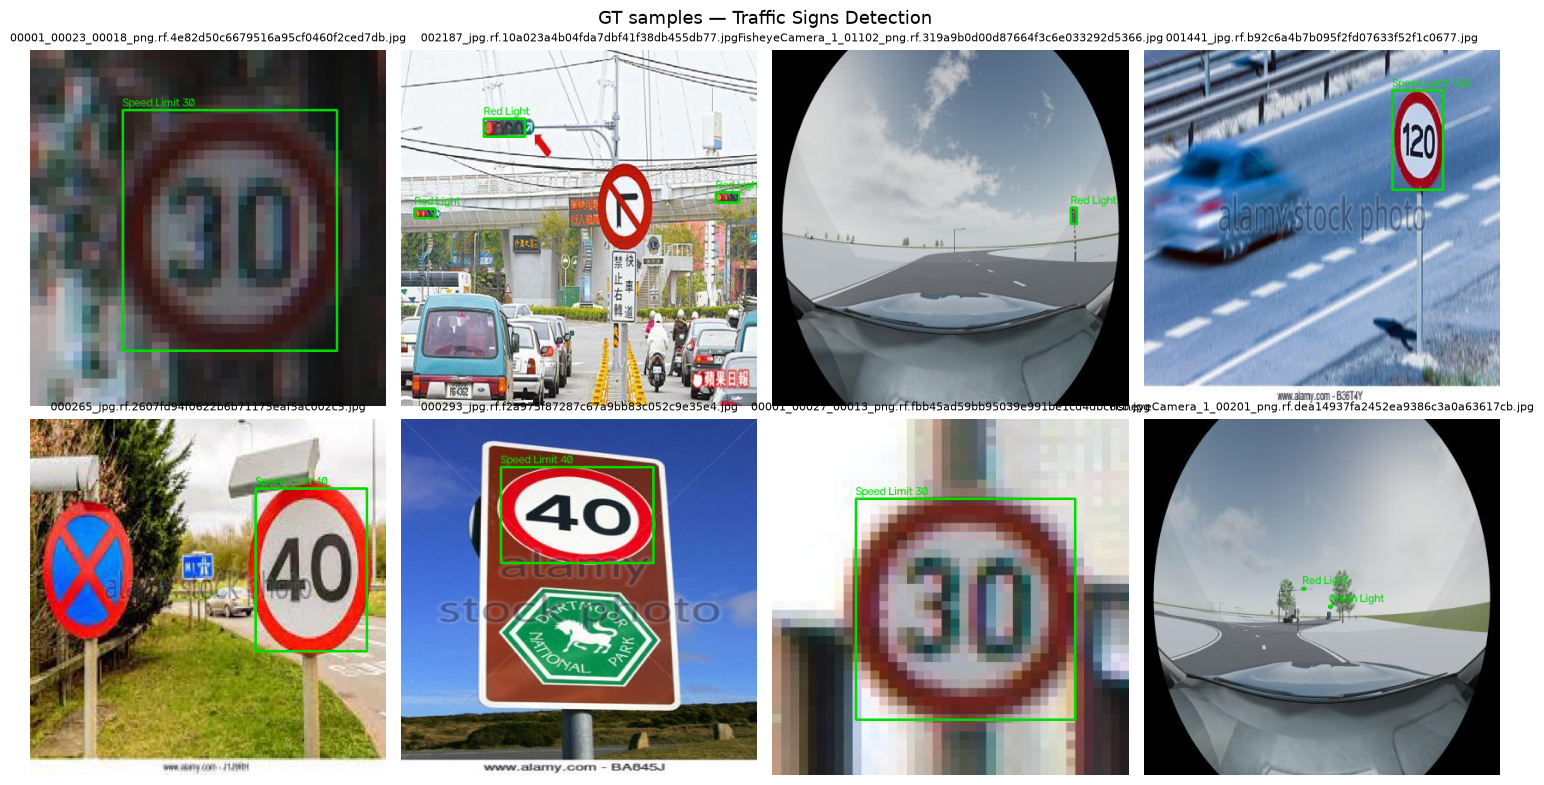

In [54]:
# 1.2 · Visualize ground-truth annotation boxes
train_imgs = sorted((DET_DIR / "train" / "images").glob("*"))
rng        = np.random.default_rng(SEED)
samples    = list(rng.choice(train_imgs, size=8, replace=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, img_path in zip(axes.ravel(), samples):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]
    lbl = (DET_DIR / "train" / "labels" / (img_path.stem + ".txt"))
    if lbl.exists():
        for line in lbl.read_text().splitlines():
            if not line.strip():
                continue
            c, cx, cy, w, h = map(float, line.split())
            x1, y1 = int((cx - w / 2) * W), int((cy - h / 2) * H)
            bw, bh = int(w * W), int(h * H)
            cv2.rectangle(img, (x1, y1), (x1 + bw, y1 + bh), (0, 220, 0), 2)
            cv2.putText(img, DET_CLASSES[int(c)], (x1, max(12, y1 - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 220, 0), 1, cv2.LINE_AA)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")
plt.suptitle("GT samples — Traffic Signs Detection", fontsize=13)
plt.tight_layout(); plt.show()

## 2 · Detection — YOLOv8 training (75 epochs)

`USE_PRETRAINED=True` → transfer learning from COCO weights; `False` → random init.
75 epochs with cosine LR, mosaic disabled over the last 15 epochs for stability,
checkpoint snapshot every 10 epochs. Expect ≈ 35–40 min on a laptop GPU (reduce
`DET_EPOCHS` on CPU).

In [55]:
# 2.1 · Build & train YOLOv8n

# — §2 self-boot — no-op when cell 0 already ran; lets this section run on a fresh kernel —
import time, random
from pathlib import Path
import numpy as np, pandas as pd, cv2, yaml
import matplotlib.pyplot as plt
import torch
if 'DET_YAML' not in globals():          # cell 0 (Setup) hasn't run in this kernel
    _root    = Path('.').resolve()
    SEED     = 42
    device   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    DET_DIR  = _root / 'database' / 'car'
    DET_YAML = DET_DIR / 'signs_data.yaml'
    assert DET_YAML.exists(), f'{DET_YAML} missing — run cell 0 + 1.1 first (Run All does this)'
    torch.manual_seed(SEED); np.random.seed(SEED)
    print('· §2 prerequisites auto-booted (cell 0 had not run in this kernel)')

from ultralytics import YOLO

USE_PRETRAINED = True          # True = transfer learning / False = train from scratch
DET_EPOCHS     = 1 if globals().get('SMOKE_TEST', False) else 75
if DET_EPOCHS == 1:
    print('⚠ SMOKE TEST — 1 epoch; set SMOKE_TEST = False in cell 0 for the full 75-epoch training')

det_model = YOLO("yolov8n.pt" if USE_PRETRAINED else "yolov8n.yaml")
print("starting weights:", "yolov8n.pt (COCO transfer)" if USE_PRETRAINED else "yolov8n.yaml (random init)")

results = det_model.train(
    data=str(DET_YAML), epochs=DET_EPOCHS, imgsz=416, batch=16,
    project="runs", name="yolov8n_traffic_signs", exist_ok=False,
    device=0 if torch.cuda.is_available() else "cpu",
    seed=SEED, patience=25, cos_lr=True, close_mosaic=15, save_period=10,
    workers=0, plots=True,
)
det_run_dir = Path(results.save_dir)
BEST_PT     = det_run_dir / "weights" / "best.pt"
print("best checkpoint →", BEST_PT)

starting weights: yolov8n.pt (COCO transfer)
New https://pypi.org/project/ultralytics/8.4.201 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\devprojects\Project Traffic signs\database\car\signs_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=75, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width

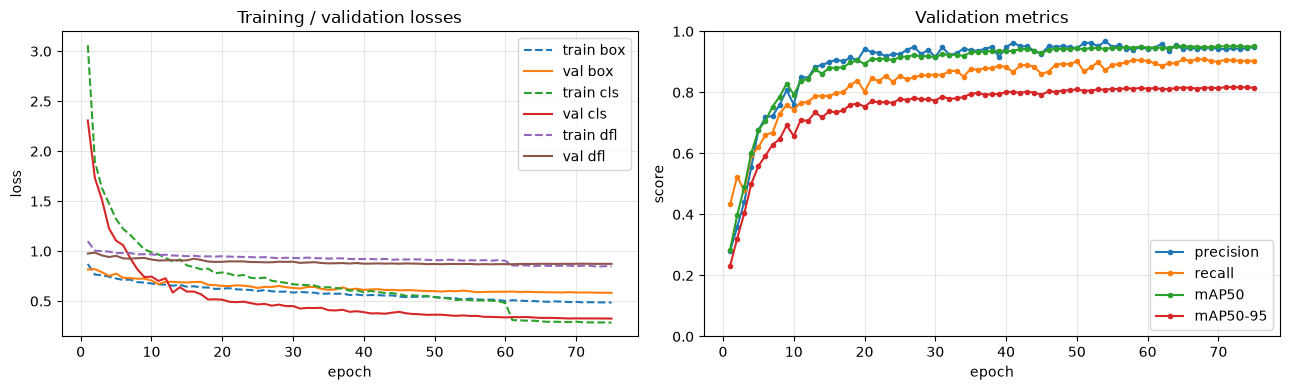

In [56]:
# 2.2 · Training curves (parsed from results.csv)
df = pd.read_csv(det_run_dir / "results.csv")
df.columns = [c.strip() for c in df.columns]
epoch = df["epoch"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for loss in ("box", "cls", "dfl"):
    ax[0].plot(epoch, df[f"train/{loss}_loss"], "--", label=f"train {loss}")
    ax[0].plot(epoch, df[f"val/{loss}_loss"],    label=f"val {loss}")
ax[0].set(title="Training / validation losses", xlabel="epoch", ylabel="loss")
ax[0].legend(); ax[0].grid(alpha=.3)

for suffix, label in (("precision(B)", "precision"), ("recall(B)", "recall"),
                      ("mAP50(B)", "mAP50"), ("mAP50-95(B)", "mAP50-95")):
    col = [c for c in df.columns if c.endswith(suffix)][0]
    ax[1].plot(epoch, df[col], marker="o", ms=3, label=label)
ax[1].set(title="Validation metrics", xlabel="epoch", ylabel="score", ylim=(0, 1))
ax[1].legend(loc="lower right"); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "yolo_training_curves.png", dpi=150)
plt.show()

In [57]:
# 2.3 · Validation & test performance (metrics table)
rows = []
for split in ("val", "test"):
    m = det_model.val(data=str(DET_YAML), split=split, verbose=False)
    rows.append({"split": split,
                 "precision": round(m.box.mp, 4), "recall": round(m.box.mr, 4),
                 "mAP50": round(m.box.map50, 4), "mAP50-95": round(m.box.map, 4)})
    if hasattr(m, "save_dir"):
        print(f"figures ({split}) →", m.save_dir)
yolo_metrics = pd.DataFrame(rows).set_index("split")
print(yolo_metrics)
yolo_metrics.to_csv(OUT_DIR / "yolo_metrics.csv")

Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 199.3±61.4 MB/s, size: 20.3 KB)
val: Scanning D:\devprojects\Project Traffic signs\database\car\valid\labels.cache... 801 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 801/801 224.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 2.7it/s 18.8s<0.1s
                   all        801        944      0.943      0.905       0.95      0.818
Speed: 0.6ms preprocess, 1.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to D:\devprojects\Project Traffic signs\runs\detect\val-8
figures (val) → D:\devprojects\Project Traffic signs\runs\detect\val-8
Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summar

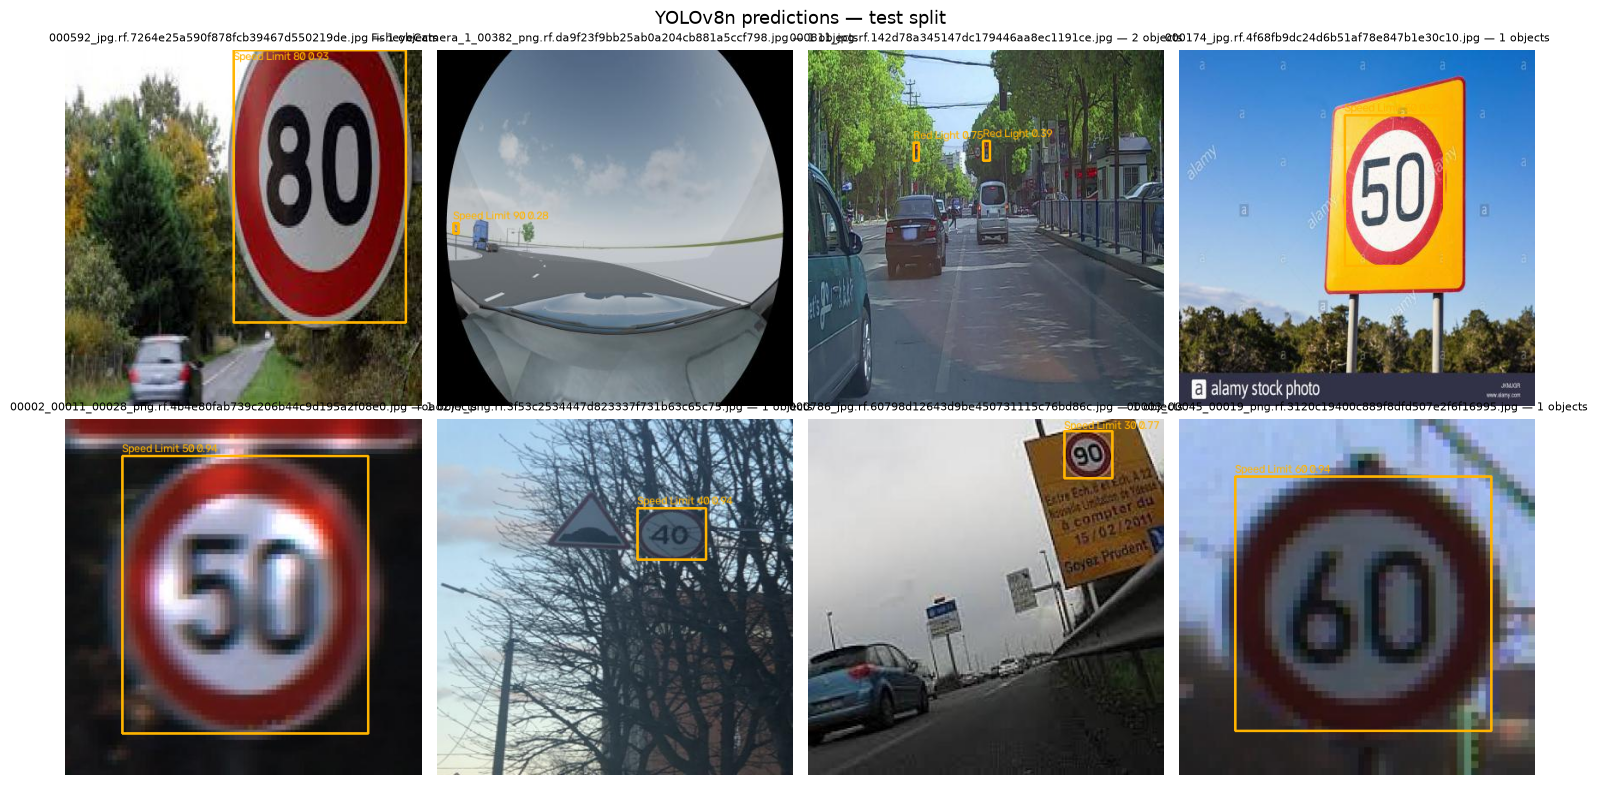

In [58]:
# 2.4 · Qualitative results on test images
test_imgs = sorted((DET_DIR / "test" / "images").glob("*"))
picks     = list(rng.choice(test_imgs, size=8, replace=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, p in zip(axes.ravel(), picks):
    img  = cv2.imread(str(p))
    r    = det_model.predict(source=img, conf=0.25, imgsz=416, verbose=False)[0]
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 180, 255), 2)
        cv2.putText(img, f"{DET_CLASSES[int(b.cls)]} {float(b.conf):.2f}",
                    (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45,
                    (0, 180, 255), 1, cv2.LINE_AA)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{p.name} — {len(r.boxes)} objects", fontsize=8)
    ax.axis("off")
plt.suptitle("YOLOv8n predictions — test split", fontsize=13)
plt.tight_layout(); plt.show()

## 3 · Classification — GTSRB CNN (from scratch)

43 classes · 48×48 · official test set untouched · fixed 90/10 train/val split shared
by all models · OneCycle LR + label smoothing + early stopping · TTA on final evaluation.

train 276 batches | val 31 | test 99 batches | classes: 43


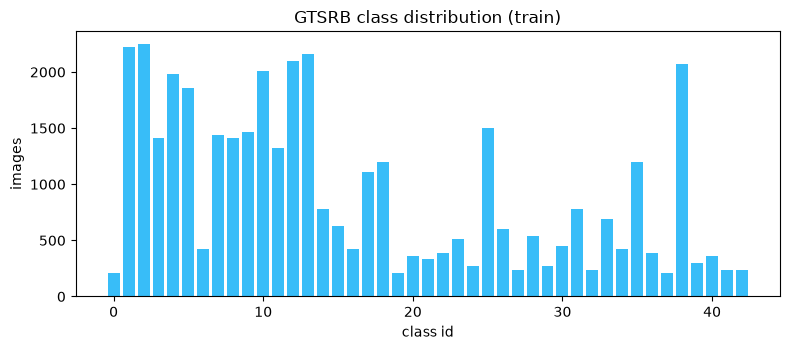

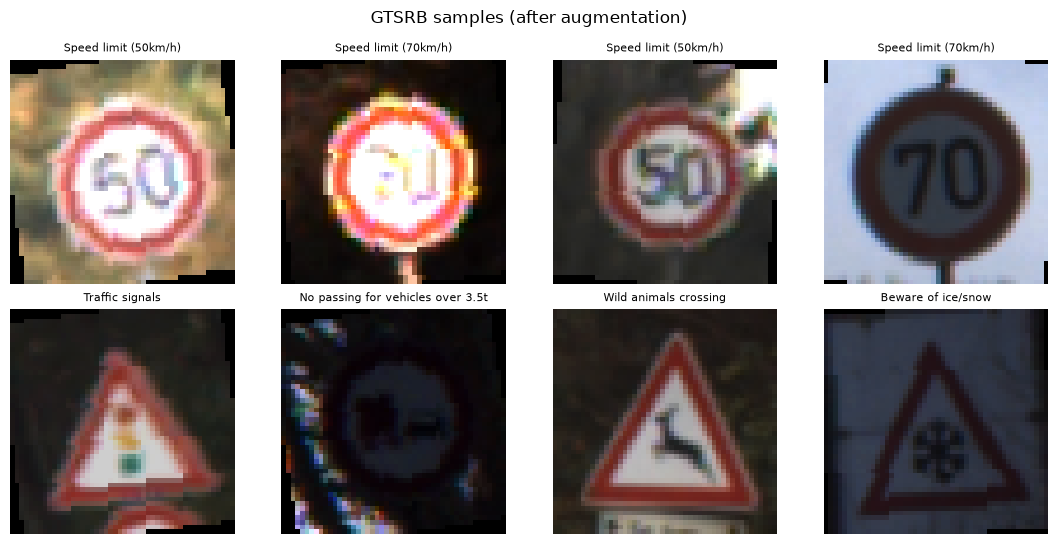

In [59]:
# 3.1 · Data — GTSRB loaders (custom CSV dataset, no downloads)

# — §3 self-boot — no-op when cell 0 already ran; lets this section run on a fresh kernel —
import random, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader, Subset, Dataset
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)

if 'GTSRB_DIR' not in globals():          # cell 0 (Setup) hasn't run in this kernel
    _root     = Path('.').resolve()
    SEED      = 42
    device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    GTSRB_DIR = _root / 'database' / 'gtsrb'
    OUT_DIR   = _root / 'outputs';  OUT_DIR.mkdir(exist_ok=True)
    MODEL_DIR = _root / 'models';   MODEL_DIR.mkdir(exist_ok=True)
    assert (GTSRB_DIR / 'Train.csv').exists(), f'GTSRB not found in {GTSRB_DIR} — run cell 0 (Setup) or Run All first'
    torch.manual_seed(SEED); np.random.seed(SEED)
    torch.backends.cudnn.benchmark = True
    print('· §3 prerequisites auto-booted (cell 0 had not run in this kernel)')

GTSRB_CLASSES = [
    "Speed limit (20km/h)", "Speed limit (30km/h)", "Speed limit (50km/h)", "Speed limit (60km/h)",
    "Speed limit (70km/h)", "Speed limit (80km/h)", "End of speed limit (80km/h)", "Speed limit (100km/h)",
    "Speed limit (120km/h)", "No passing", "No passing for vehicles over 3.5t", "Right-of-way at next intersection",
    "Priority road", "Yield", "Stop", "No vehicles", "Vehicles over 3.5t prohibited", "No entry",
    "General caution", "Dangerous curve left", "Dangerous curve right", "Double curve", "Bumpy road",
    "Slippery road", "Road narrows right", "Road work", "Traffic signals", "Pedestrians", "Children crossing",
    "Bicycles crossing", "Beware of ice/snow", "Wild animals crossing", "End of all restrictions",
    "Turn right ahead", "Turn left ahead", "Ahead only", "Go straight or right", "Go straight or left",
    "Keep right", "Keep left", "Roundabout mandatory", "End of no passing", "End of no passing over 3.5t"]

class GTSRBCsv(Dataset):
    def __init__(self, csv_file, transform=None):
        df = pd.read_csv(csv_file)
        self.imgs      = df["Path"].astype(str).tolist()
        self.labels    = df["ClassId"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        img = Image.open(GTSRB_DIR / self.imgs[i]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[i]

N_CLASSES = 43
IMG_SIZE  = 48

gtsrb_train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ColorJitter(brightness=.25, contrast=.25, saturation=.15),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
gtsrb_eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

# fixed 90/10 train/val permutation shared by every model → fair comparison
_perm = torch.randperm(len(pd.read_csv(GTSRB_DIR / "Train.csv")),
                       generator=torch.Generator().manual_seed(SEED)).tolist()
_tr_idx, _va_idx = _perm[:-int(0.1 * len(_perm))], _perm[-int(0.1 * len(_perm)):]

def make_gtsrb_loaders(train_tf, eval_tf, batch_size=128):
    tr = GTSRBCsv(GTSRB_DIR / "Train.csv", train_tf)
    va = GTSRBCsv(GTSRB_DIR / "Train.csv", eval_tf)
    te = GTSRBCsv(GTSRB_DIR / "Test.csv",  eval_tf)
    pin = device.type == "cuda"
    return (DataLoader(Subset(tr, _tr_idx), batch_size, shuffle=True,  pin_memory=pin, num_workers=0),
            DataLoader(Subset(va, _va_idx), batch_size, shuffle=False, pin_memory=pin, num_workers=0),
            DataLoader(te, batch_size, shuffle=False, pin_memory=pin, num_workers=0))

gtsrb_loaders = make_gtsrb_loaders(gtsrb_train_tf, gtsrb_eval_tf)
print("train", len(gtsrb_loaders[0]), "batches | val", len(gtsrb_loaders[1]),
      "| test", len(gtsrb_loaders[2]), "batches | classes:", N_CLASSES)

# class balance + sample viz
cls_counts = pd.read_csv(GTSRB_DIR / "Train.csv")["ClassId"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(N_CLASSES), cls_counts, color="#38bdf8")
ax.set(title="GTSRB class distribution (train)", xlabel="class id", ylabel="images")
plt.tight_layout(); plt.savefig(OUT_DIR / "gtsrb_class_balance.png", dpi=150); plt.show()

xb, yb = next(iter(gtsrb_loaders[0]))
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, i in zip(axes.ravel(), np.random.default_rng(SEED).choice(len(xb), size=8, replace=False)):
    img = xb[i].numpy().transpose(1, 2, 0) * 0.5 + 0.5
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(GTSRB_CLASSES[int(yb[i])], fontsize=8); ax.axis("off")
plt.suptitle("GTSRB samples (after augmentation)", fontsize=12)
plt.tight_layout(); plt.show()

In [60]:
# 3.2 · Model — compact CNN, trained from scratch
class TrafficSignCNN(nn.Module):
    def __init__(self, n_classes=N_CLASSES, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.BatchNorm2d(32),  nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),  nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Dropout(dropout))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 6 * 6, 256), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(256, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

model_scratch = TrafficSignCNN().to(device)
n_params = sum(p.numel() for p in model_scratch.parameters())
print(f"parameters: {n_params/1e6:.2f} M")

with torch.no_grad():                                   # dry-run forward
    dummy = torch.randn(4, 3, IMG_SIZE, IMG_SIZE, device=device)
    print("output shape:", tuple(model_scratch(dummy).shape))

parameters: 1.28 M
output shape: (4, 43)


In [61]:
# 3.3 · Shared training / evaluation helpers
#     OneCycle LR, label smoothing, early stopping (patience 8), TTA evaluation
def fit(model, loaders, epochs, lr, name):
    tr_dl, va_dl, _ = loaders
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)
    opt   = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr * 3,
                                                total_steps=epochs * len(tr_dl), pct_start=0.2)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_path, best_acc, stale = MODEL_DIR / f"{name}.pth", 0.0, 0
    t0 = time.time()

    for ep in range(1, epochs + 1):
        model.train(); te, tc, tl = 0, 0, 0.0
        for xb, yb in tr_dl:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward(); opt.step(); sched.step()
            tl += loss.item() * len(xb); tc += (pred.argmax(1) == yb).sum().item(); te += len(xb)

        model.eval(); ve, vc, vl = 0, 0, 0.0
        with torch.no_grad():
            for xb, yb in va_dl:
                xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
                pred = model(xb)
                vl += loss_fn(pred, yb).item() * len(xb)
                vc += (pred.argmax(1) == yb).sum().item(); ve += len(xb)

        hist["train_loss"].append(tl / te); hist["train_acc"].append(tc / te)
        hist["val_loss"].append(vl / ve);   hist["val_acc"].append(vc / ve)
        star = ""
        if hist["val_acc"][-1] > best_acc:
            best_acc, stale = hist["val_acc"][-1], 0
            torch.save(model.state_dict(), best_path); star = "  ★ saved"
        else:
            stale += 1
        print(f"epoch {ep:2d}/{epochs} | train loss {tl/te:.4f} acc {tc/te:.4f} "
              f"| val loss {vl/ve:.4f} acc {vc/ve:.4f}{star}")
        if stale >= 8:
            print(f"early stopping (no val improvement for {stale} epochs)")
            break

    model.load_state_dict(torch.load(best_path, map_location=device))
    torch.save({"classes": GTSRB_CLASSES, "img_size": IMG_SIZE, "name": name},
               MODEL_DIR / f"{name}_meta.pt")
    print(f"\nbest val accuracy: {best_acc:.4f}  ({time.time()-t0:.0f}s total → {best_path})")
    return hist

def collect_preds(model, test_dl, tta=True):
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for xb, yb in test_dl:
            x = xb.to(device, non_blocking=True)
            logits = model(x)
            if tta:
                z = F.interpolate(x, scale_factor=1.12, mode="bilinear", align_corners=False)
                d = (z.size(2) - x.size(2)) // 2
                logits = logits + model(z[:, :, d:d + x.size(2), d:d + x.size(3)])
                s = torch.roll(x, shifts=(1, 1), dims=(2, 3))
                logits = logits + model(s)
            y_pred += logits.argmax(1).cpu().tolist()
            y_true += yb.tolist()
    return y_true, y_pred

def eval_classifier(model, test_dl, name, tta=True):
    y_true, y_pred = collect_preds(model, test_dl, tta=tta)
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average="macro")
    f1w = f1_score(y_true, y_pred, average="weighted")
    print(f"{name}: test accuracy={acc:.4f} | macro-F1={f1m:.4f} | weighted-F1={f1w:.4f}"
          f"{' (TTA)' if tta else ''}")

    report = classification_report(y_true, y_pred, target_names=GTSRB_CLASSES,
                                   digits=3, zero_division=0)
    print(report)
    with open(OUT_DIR / f"classification_report_{name}.txt", "w", encoding="utf-8") as f:
        f.write(report)

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(9.5, 8))
    im = ax.imshow(cm, cmap="viridis")
    fig.colorbar(im, ax=ax, fraction=.046)
    ax.set(title=f"Confusion matrix — {name}", xlabel="predicted class", ylabel="true class")
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(range(N_CLASSES), fontsize=6); ax.set_yticklabels(range(N_CLASSES), fontsize=6)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"confusion_matrix_{name}.png", dpi=150); plt.show()

    _, rec, _, _ = precision_recall_fscore_support(y_true, y_pred, zero_division=0)
    worst = (pd.Series(rec, index=GTSRB_CLASSES).sort_values().head(8) * 100).round(1)
    print("· classes with the lowest recall (%):"); print(worst.to_string())
    return {"model": name, "test_acc": round(float(acc), 4),
            "macro_f1": round(float(f1m), 4), "weighted_f1": round(float(f1w), 4)}

In [3]:
# 3.4 · Train the scratch CNN
EPOCHS = 1 if globals().get('SMOKE_TEST', False) else 75
if EPOCHS == 1:
    print('⚠ SMOKE TEST — 1 epoch; set SMOKE_TEST = False in cell 0 for the full 30-epoch training')
hist_scratch = fit(model_scratch, gtsrb_loaders, epochs=EPOCHS, lr=1e-3, name="gtsrb_cnn_scratch")

e = range(1, len(hist_scratch["val_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(e, hist_scratch["train_loss"], "--", label="train")
ax[0].plot(e, hist_scratch["val_loss"], label="val")
ax[0].set(title="Loss", xlabel="epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(e, hist_scratch["train_acc"], "--", label="train")
ax[1].plot(e, hist_scratch["val_acc"], label="val")
ax[1].set(title="Accuracy", xlabel="epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "cnn_scratch_curves.png", dpi=150); plt.show()

NameError: name 'fit' is not defined

cnn_scratch: test accuracy=0.9937 | macro-F1=0.9918 | weighted-F1=0.9937 (TTA)
                                   precision    recall  f1-score   support

             Speed limit (20km/h)      1.000     1.000     1.000        60
             Speed limit (30km/h)      0.993     1.000     0.997       720
             Speed limit (50km/h)      0.999     0.997     0.998       750
             Speed limit (60km/h)      0.998     0.967     0.982       450
             Speed limit (70km/h)      1.000     0.995     0.998       660
             Speed limit (80km/h)      0.972     0.994     0.983       630
      End of speed limit (80km/h)      1.000     0.980     0.990       150
            Speed limit (100km/h)      0.991     0.998     0.994       450
            Speed limit (120km/h)      0.998     0.998     0.998       450
                       No passing      0.992     0.998     0.995       480
No passing for vehicles over 3.5t      0.997     0.997     0.997       660
Right-of-way at next

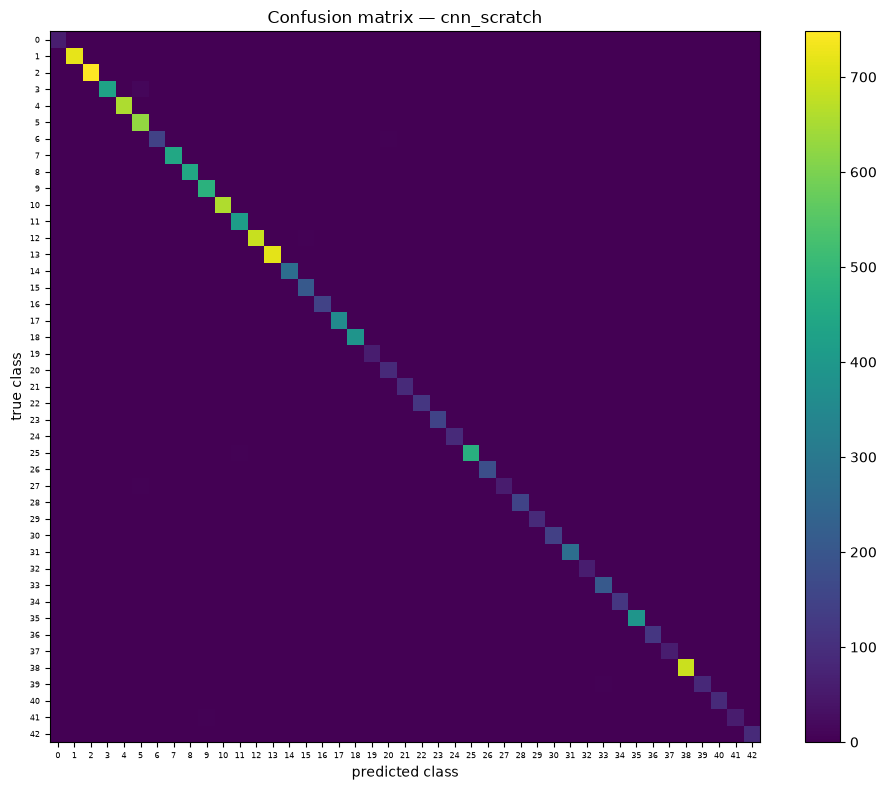

· classes with the lowest recall (%):
Pedestrians                    95.0
End of no passing              95.0
Beware of ice/snow             95.3
Speed limit (60km/h)           96.7
Keep left                      96.7
Road narrows right             97.8
End of speed limit (80km/h)    98.0
Bumpy road                     98.3


In [ ]:
# 3.5 · Official test evaluation (TTA)
scratch_score = eval_classifier(model_scratch, gtsrb_loaders[2], name="cnn_scratch")

## 4 · Transfer learning variant — ResNet18 (comparison)

ImageNet-pretrained backbone (frozen except `layer4`), new 43-class head, 6 epochs —
compared against the scratch CNN on the same split (TTA evaluation).

epoch  1/6 | train loss 1.4400 acc 0.6679 | val loss 0.8309 acc 0.8599  ★ saved
epoch  2/6 | train loss 0.6922 acc 0.9041 | val loss 0.5527 acc 0.9487  ★ saved
epoch  3/6 | train loss 0.5372 acc 0.9567 | val loss 0.4828 acc 0.9722  ★ saved
epoch  4/6 | train loss 0.4597 acc 0.9812 | val loss 0.4323 acc 0.9865  ★ saved
epoch  5/6 | train loss 0.4228 acc 0.9926 | val loss 0.4097 acc 0.9944  ★ saved
epoch  6/6 | train loss 0.4098 acc 0.9964 | val loss 0.4083 acc 0.9936

best val accuracy: 0.9944  (281s total → D:\devprojects\Project Traffic signs\models\gtsrb_resnet18_tl.pth)
resnet18_tl: test accuracy=0.8768 | macro-F1=0.8227 | weighted-F1=0.8743 (TTA)
                                   precision    recall  f1-score   support

             Speed limit (20km/h)      0.875     0.350     0.500        60
             Speed limit (30km/h)      0.770     0.822     0.795       720
             Speed limit (50km/h)      0.738     0.780     0.758       750
             Speed limit (60km/h)      0

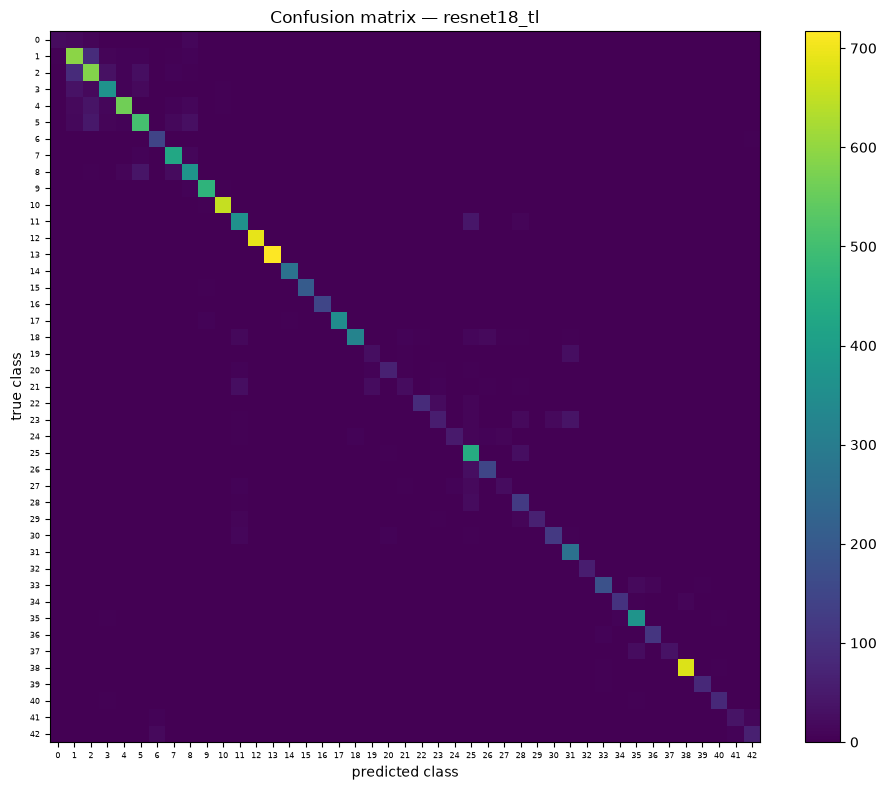

· classes with the lowest recall (%):
Double curve            26.7
Speed limit (20km/h)    35.0
Slippery road           38.7
Pedestrians             41.7
Dangerous curve left    43.3
Go straight or left     56.7
Road narrows right      58.9
End of no passing       63.3


In [ ]:
# 4.1 · Train ResNet18 (transfer learning)
TL_IMG_SIZE = 64
tl_train_tf = transforms.Compose([
    transforms.Resize((TL_IMG_SIZE, TL_IMG_SIZE)), transforms.ColorJitter(brightness=.2, contrast=.2),
    transforms.RandomRotation(10), transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
tl_eval_tf = transforms.Compose([
    transforms.Resize((TL_IMG_SIZE, TL_IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
tl_loaders = make_gtsrb_loaders(tl_train_tf, tl_eval_tf)

model_tl = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in model_tl.parameters():
    p.requires_grad = False                 # freeze pretrained backbone
for p in model_tl.layer4.parameters():
    p.requires_grad = True                  # unfreeze the last block
model_tl.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model_tl.fc.in_features, N_CLASSES))
model_tl = model_tl.to(device)

TL_EPOCHS = 1 if globals().get('SMOKE_TEST', False) else 6
if TL_EPOCHS == 1:
    print('⚠ SMOKE TEST — 1 epoch; set SMOKE_TEST = False in cell 0 for the full 6-epoch training')
hist_tl   = fit(model_tl, tl_loaders, epochs=TL_EPOCHS, lr=8e-4, name="gtsrb_resnet18_tl")
tl_score  = eval_classifier(model_tl, tl_loaders[2], name="resnet18_tl")

In [ ]:
# 4.2 · Scratch CNN vs transfer learning
comparison = pd.DataFrame([scratch_score, tl_score]).set_index("model")
print(comparison)
comparison.to_csv(OUT_DIR / "classification_comparison.csv")
print("\n✔ winner by test accuracy:", comparison["test_acc"].idxmax())

             test_acc  macro_f1  weighted_f1
model                                       
cnn_scratch    0.9937    0.9918       0.9937
resnet18_tl    0.8768    0.8227       0.8743

✔ winner by test accuracy: cnn_scratch


## 5 · Fusion — panneau détecté, classe prédite

YOLOv8 finds the panels → each crop is classified by the GTSRB CNN.
*(GTSRB has no light classes — the CNN label on light crops is informational only.)*

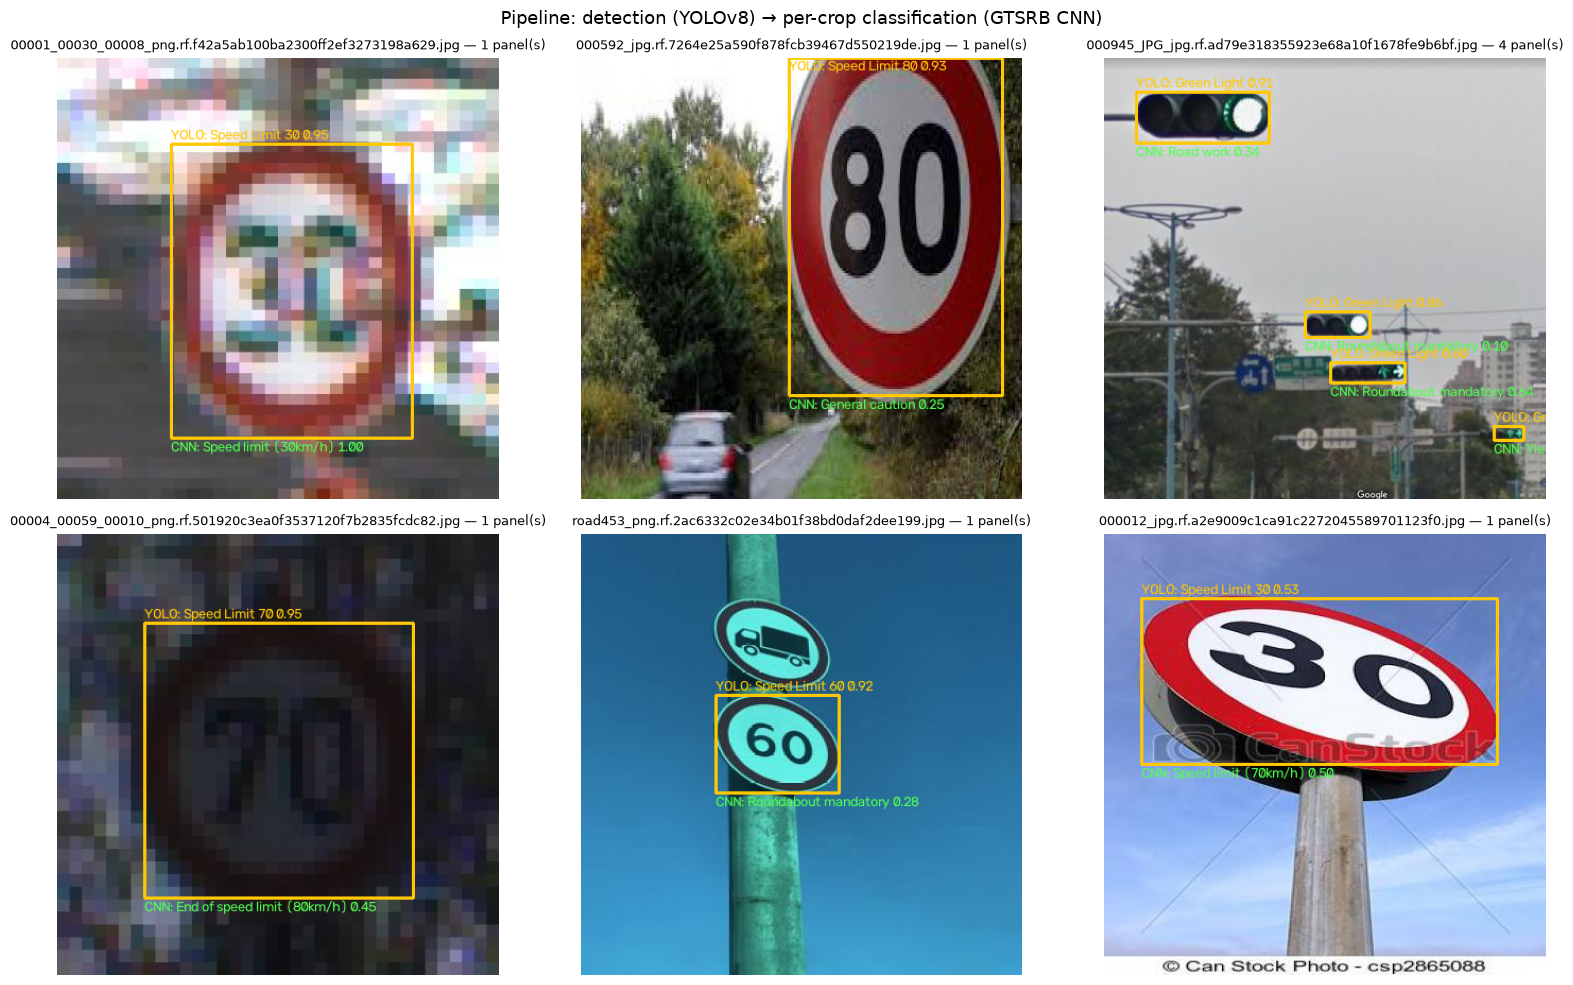

In [ ]:
# 5.1 · Detect → crop → classify → annotate
det_model = YOLO(str(BEST_PT))                       # fresh load of the best YOLO weights
clf_model = TrafficSignCNN().to(device)
clf_model.load_state_dict(torch.load(MODEL_DIR / "gtsrb_cnn_scratch.pth", map_location=device))
clf_model.eval()

def classify_crop(rgb_crop):
    x = gtsrb_eval_tf(Image.fromarray(rgb_crop)).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = clf_model(x)
        z = F.interpolate(x, scale_factor=1.12, mode="bilinear", align_corners=False)
        d = (z.size(2) - x.size(2)) // 2
        logits = logits + clf_model(z[:, :, d:d + x.size(2), d:d + x.size(3)])
        probs = logits.softmax(1)[0]
    conf, cls_idx = probs.max(0)
    return GTSRB_CLASSES[int(cls_idx)], float(conf)

def detect_and_classify(img_bgr, conf_th=0.30):
    res = det_model.predict(source=img_bgr, conf=conf_th, imgsz=416, verbose=False)[0]
    H, W = img_bgr.shape[:2]
    out = img_bgr.copy()
    for b in res.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W - 1, x2), min(H - 1, y2)
        rgb_crop = cv2.cvtColor(out[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
        label2 = ""
        if rgb_crop.size and min(x2 - x1, y2 - y1) > 8:
            cnn_name, cnn_conf = classify_crop(rgb_crop)
            label2 = f"CNN: {cnn_name} {cnn_conf:.2f}"
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 200, 255), 2)
        cv2.putText(out, f"YOLO: {DET_CLASSES[int(b.cls)]} {float(b.conf):.2f}",
                    (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 200, 255), 1, cv2.LINE_AA)
        cv2.putText(out, label2, (x1, y2 + 13), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (80, 255, 80), 1, cv2.LINE_AA)
    return out, len(res.boxes)

picks = list(rng.choice(test_imgs, size=6, replace=False))
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, p in zip(axes.ravel(), picks):
    img = cv2.imread(str(p))
    img, n_obj = detect_and_classify(img)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{p.name} — {n_obj} panel(s)", fontsize=9); ax.axis("off")
plt.suptitle("Pipeline: detection (YOLOv8) → per-crop classification (GTSRB CNN)", fontsize=13)
plt.tight_layout(); plt.savefig(OUT_DIR / "pipeline_demo.png", dpi=150); plt.show()

## 6 · Statistics & plots — full analytics dashboard

Dataset balance, per-class detection quality (AP50), label-noise style error analysis
of the classifier (most confusable class pairs) and the head-to-head model summary.

images per split : {'train': 3530, 'valid': 801, 'test': 638}
objects per split: {'train': np.int64(4298), 'valid': np.int64(944), 'test': np.int64(770)}


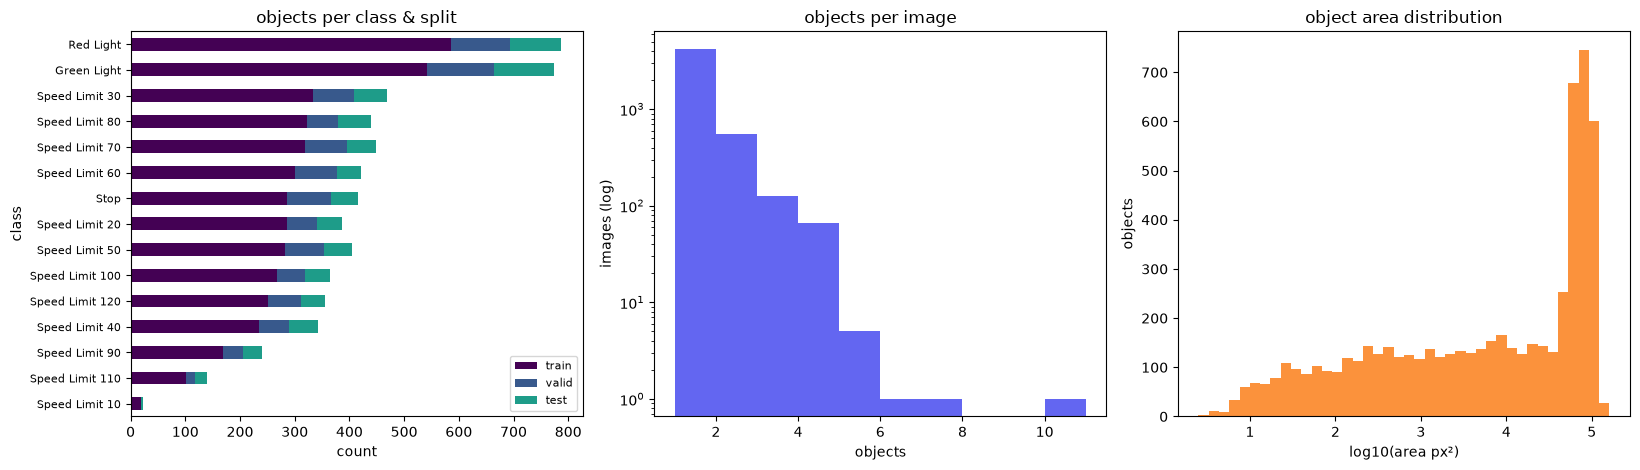

In [ ]:
def label_records():
    recs, per_img = [], []
    for split in ("train", "valid", "test"):
        for p in (DET_DIR / split / "labels").glob("*.txt"):
            lines = [l for l in p.read_text().splitlines() if l.strip()]
            per_img.append(len(lines))
            for l in lines:
                c, cx, cy, w, h = map(float, l.split())
                recs.append({"split": split, "class": DET_CLASSES[int(c)], "area": w * h * 416 * 416})
    return recs, per_img

recs, per_img = label_records()
ddf = pd.DataFrame(recs)
areas = ddf["area"].to_numpy()
count_tbl = ddf.pivot_table(index="class", columns="split", values="area", aggfunc="size")[["train", "valid", "test"]].fillna(0).astype(int)
img_counts = {s: len(list((DET_DIR / s / "images").glob("*"))) for s in ("train", "valid", "test")}
print("images per split :", img_counts)
print("objects per split:", dict(count_tbl.sum(axis=0)))
count_tbl.to_csv(OUT_DIR / "dataset_class_counts.csv")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))
count_tbl.sort_values("train").plot.barh(ax=axes[0], stacked=True, color=plt.cm.viridis(np.linspace(0, .55, 3)))
axes[0].set(title="objects per class & split", xlabel="count")
axes[0].legend(title=None, fontsize=8)
axes[0].tick_params(axis="y", labelsize=8)

axes[1].hist([f for f in per_img], bins=np.arange(1, max(per_img) + 2), color="#6366f1", log=True)
axes[1].set(title="objects per image", xlabel="objects", ylabel="images (log)")

axes[2].hist(np.log10(np.array(areas) + 1), bins=40, color="#fb923c")
axes[2].set(title="object area distribution", xlabel="log10(area px²)", ylabel="objects")
plt.tight_layout(); plt.savefig(OUT_DIR / "dataset_stats.png", dpi=150); plt.show()

Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 181.4±74.9 MB/s, size: 23.3 KB)
val: Scanning D:\devprojects\Project Traffic signs\database\car\test\labels.cache... 638 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 638/638 191.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.1it/s 19.3s<0.1s
                   all        638        770      0.935      0.909      0.946        0.8
Speed: 0.8ms preprocess, 1.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to D:\devprojects\Project Traffic signs\runs\detect\val-10
          class  AP50
      Red Light 0.717
    Green Light 0.884
Speed Limit 110 0.885
 Speed Limit 50 0.919
 Speed Limit 70 0.954
 Speed Limit 60 0.969
 Speed Limit 20 0.975
 Speed Limit 4

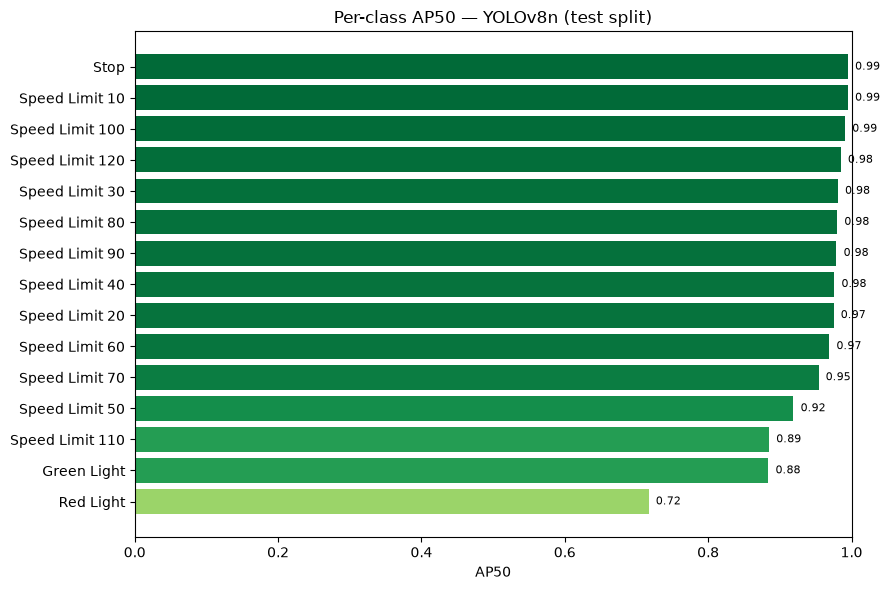

In [ ]:
# 6.2 · Per-class detection quality — AP50 on the test split
m_test = det_model.val(data=str(DET_YAML), split="test", verbose=False)
ap50 = np.nan_to_num(np.asarray(m_test.box.ap50, dtype=float), nan=0.0)  # per-class AP@IoU0.5
ap_df = (pd.DataFrame({"class": DET_CLASSES, "AP50": np.round(ap50, 3)})
          .sort_values("AP50"))
print(ap_df.to_string(index=False))
ap_df.to_csv(OUT_DIR / "per_class_ap50.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.cm.RdYlGn(np.clip(ap_df["AP50"].values, 0, 1))
ax.barh(ap_df["class"], ap_df["AP50"], color=colors)
ax.set(title="Per-class AP50 — YOLOv8n (test split)", xlabel="AP50", xlim=(0, 1))
for y, v in enumerate(ap_df["AP50"]):
    ax.text(v + .01, y, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "per_class_ap50.png", dpi=150); plt.show()

top confusions (scratch CNN, test):
                             true                         predicted  n_misses
             Speed limit (60km/h)              Speed limit (80km/h)        14
                    Priority road                       No vehicles         5
                        Road work Right-of-way at next intersection         4
                End of no passing                        No passing         3
                      Pedestrians              Speed limit (80km/h)         3
                        Keep left                  Turn right ahead         3
      End of speed limit (80km/h)             Dangerous curve right         3
                  General caution                   Traffic signals         2
               Beware of ice/snow             Dangerous curve right         2
               Beware of ice/snow                         Road work         2
Right-of-way at next intersection                Beware of ice/snow         2
             Speed limit (50

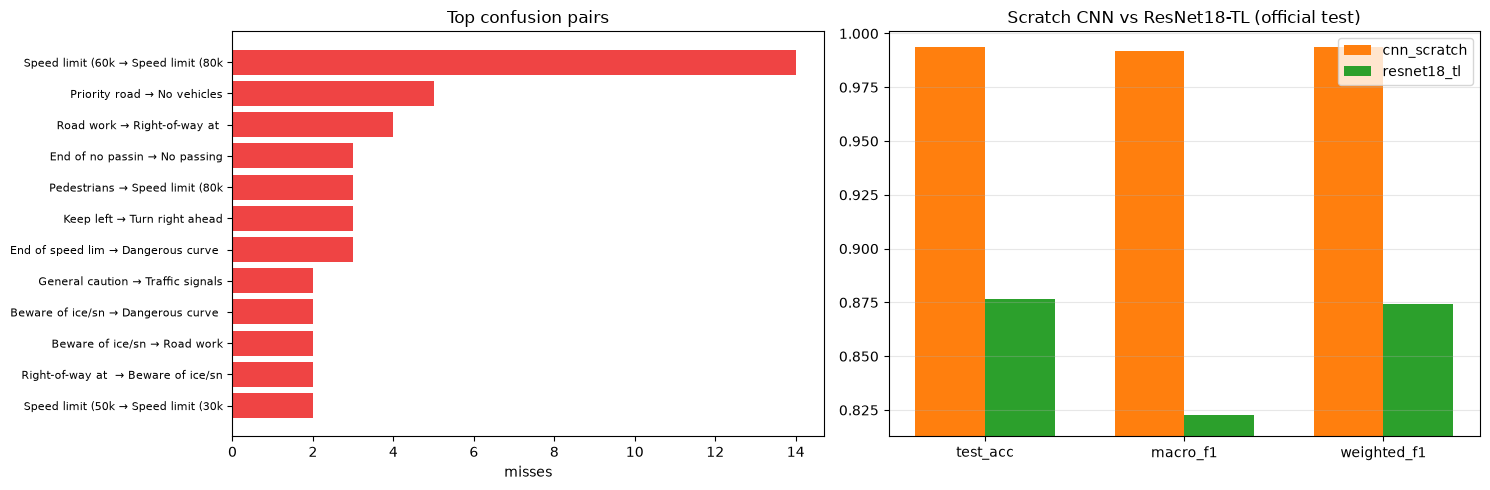

In [ ]:
# 6.3 · Classifier error analysis — most confusable GTSRB pairs + head-to-head bar
y_true, y_pred = collect_preds(model_scratch, gtsrb_loaders[2])
cm = confusion_matrix(y_true, y_pred).copy()
np.fill_diagonal(cm, 0)
flat = np.argsort(cm.ravel())[::-1][:12]
i_arr, j_arr = np.unravel_index(flat, cm.shape)
pairs = [{"true": GTSRB_CLASSES[i], "predicted": GTSRB_CLASSES[j], "n_misses": int(cm[i, j])}
         for i, j in zip(i_arr, j_arr)]
pairs_df = pd.DataFrame(pairs)
print("top confusions (scratch CNN, test):"); print(pairs_df.to_string(index=False))
pairs_df.to_csv(OUT_DIR / "cnn_confusion_pairs.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(range(len(pairs_df))[::-1], pairs_df["n_misses"], color="#ef4444")
axes[0].set_yticks(range(len(pairs_df))[::-1])
axes[0].set_yticklabels([f"{t[:16]} → {p[:16]}" for t, p in
                         zip(pairs_df["true"], pairs_df["predicted"])], fontsize=8)
axes[0].set(title="Top confusion pairs", xlabel="misses")

x = np.arange(len(comparison.columns)); w = 0.35
for k, (name, row) in enumerate(comparison.iterrows()):
    axes[1].bar(x + (k - .5) * w, row.values, w, label=name,
                color=plt.cm.tab10(k + 1))
axes[1].set_xticks(x); axes[1].set_xticklabels(comparison.columns)
axes[1].set(ylim=(min(.95, comparison.values.min() - .01), 1.001),
            title="Scratch CNN vs ResNet18-TL (official test)")
axes[1].legend(); axes[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "cnn_error_analysis.png", dpi=150); plt.show()

## 7 · Wrap-up

| Requirement (*énoncé*) | Where it is answered |
|---|---|
| **Panneau détecté** | YOLOv8n boxes — §2.4 / §5 visuals |
| **Classe prédite** | YOLO class + GTSRB CNN class per crop — §3 / §5 |
| **Évaluation des performances** | detection: P / R / mAP50 / mAP50-95 (§2.3) + per-class AP50 (§6.2) · classification: accuracy/F1/administrative confusion matrices (§3.5, §4.1), head-to-head (§4.2), error pairs (§6.3) |
| **Statistiques** | dataset balance, object sizes, objects/image — §6.1 |
| **Techniques** | CNN from scratch (OneCycle, label smoothing, TTA), transfer learning (COCO + ResNet18) — §2 / §3 / §4 |

**Files produced**
* `runs/.../weights/best.pt` — detector · `models/*.pth` — classifiers
* `outputs/` — metrics CSVs, training curves, confusion matrices, per-class AP, error analysis, dataset stats, pipeline demo

**To go further** — larger detector (`yolov8s`), fully fresh detection (`USE_PRETRAINED=False`),
unfreeze the whole ResNet backbone, stronger crop augmentation.
Cite: GTSRB — J. Stallkamp *et al.*, 2011 · detection dataset: CC BY 4.0 (`pkdarabi/cardetection`).